# Lab 2 · Classification: EOR screening
**Slides:** Module 06 and 07 (classification metrics, ROC)  ·  **Time:** 75 min

455 field projects worldwide, each with the EOR method that was applied: CO₂, hydrocarbon or nitrogen gas injection,
polymer flooding, in-situ combustion or steam. From six reservoir properties we predict the method, then compare the
machine-learning screen with the classic **Taber screening rules**.

**You will:** handle imbalanced classes · compare classifiers · read confusion matrices · understand micro, macro and weighted averages · screen a new field.

In [1]:
# --- setup: works locally and in Google Colab ---
import os, sys
if "google.colab" in sys.modules and not os.path.exists("aiml"):
    print("Upload the course kit zip to Colab, then unzip it:  !unzip -q aiml_course_kit.zip && %cd aiml_course_kit")
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
DATA = "../data" if os.path.exists("../data") else "data"

from aiml.data import load_eor, EOR_FEATURES, EOR_CLASSES
from aiml.models import classifiers
from aiml.evaluate import compare, confusion, classification_metrics, importance
from aiml.generators import taber_screen, TABER
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
df = load_eor(log_viscosity=True)
print(df.eor_method.value_counts())

eor_method
Steam Injection    197
CO2                155
Hydrocarbon         50
Polymer             27
Combustion          19
Nitrogen             7
Name: count, dtype: int64


## 1 · Inputs: raw or log?
Viscosity runs from 0.1 to 5,000,000 cP. Trees do not care about scale; distance-based models (KNN, SVC, MLP) do.

In [2]:
F_RAW = EOR_FEATURES
F_LOG = ["log_permeability", "depth_ft", "api_gravity", "log_viscosity", "temperature_F", "oil_saturation_pct"]
y = df.eor_method
tr, te = train_test_split(df.index, test_size=0.2, random_state=42, stratify=y)
for name in ["KNN", "SVC", "Random forest"]:
    m = classifiers()[name]
    a = m.fit(df.loc[tr, F_RAW], y[tr]).score(df.loc[te, F_RAW], y[te]); b = m.fit(df.loc[tr, F_LOG], y[tr]).score(df.loc[te, F_LOG], y[te])
    print(f"{name:<14} raw inputs {a:.3f}   log inputs {b:.3f}")

KNN            raw inputs 0.923   log inputs 0.945
SVC            raw inputs 0.934   log inputs 0.923


Random forest  raw inputs 0.945   log inputs 0.956


## 2 · Compare classifiers
With imbalanced classes, accuracy hides the small classes; sort by **macro F1** (every class counts the same).

In [3]:
X_train, X_test, y_train, y_test = df.loc[tr, F_LOG], df.loc[te, F_LOG], y[tr], y[te]
res = compare(classifiers(), X_train, y_train, X_test, y_test, task="classification")
res[["model", "acc_train", "accuracy_test", "F1_macro_test", "F1_micro_test", "F1_weighted_test", "ROC_AUC_ovr_test"]]

,model,acc_train,accuracy_test,F1_macro_test,F1_micro_test,F1_weighted_test,ROC_AUC_ovr_test
0,Random forest,1.0000,0.9560,0.7941,0.9560,0.9503,0.9646
1,AdaBoost,0.9945,0.9451,0.7729,0.9451,0.9400,0.8988
2,Voting (soft),1.0000,0.9451,0.7689,0.9451,0.9373,0.9595
3,Extra trees,1.0000,0.9341,0.7635,0.9341,0.9264,0.9828
4,KNN,1.0000,0.9451,0.7437,0.9451,0.9422,0.8918
5,Neural network (MLP),0.9890,0.9341,0.7357,0.9341,0.9296,0.8855
6,Gradient boosting,1.0000,0.9231,0.7318,0.9231,0.9124,0.9922
7,Decision tree,0.9753,0.9231,0.7209,0.9231,0.9191,0.8330
8,SVC,0.9560,0.9231,0.7068,0.9231,0.9157,0.9550
9,Logistic regression,0.8956,0.8681,0.5170,0.8681,0.8344,0.8886


**Micro** averaging pools all predictions (equals accuracy for single-label problems). **Macro** averages the per-class
scores, so Nitrogen (7 projects) counts as much as Steam (197). **Weighted** averages by class size. The course
figures `Micro_Average.JPG`, `Macro_Average.JPG` and `Weighted_Average.JPG` show the same three numbers.

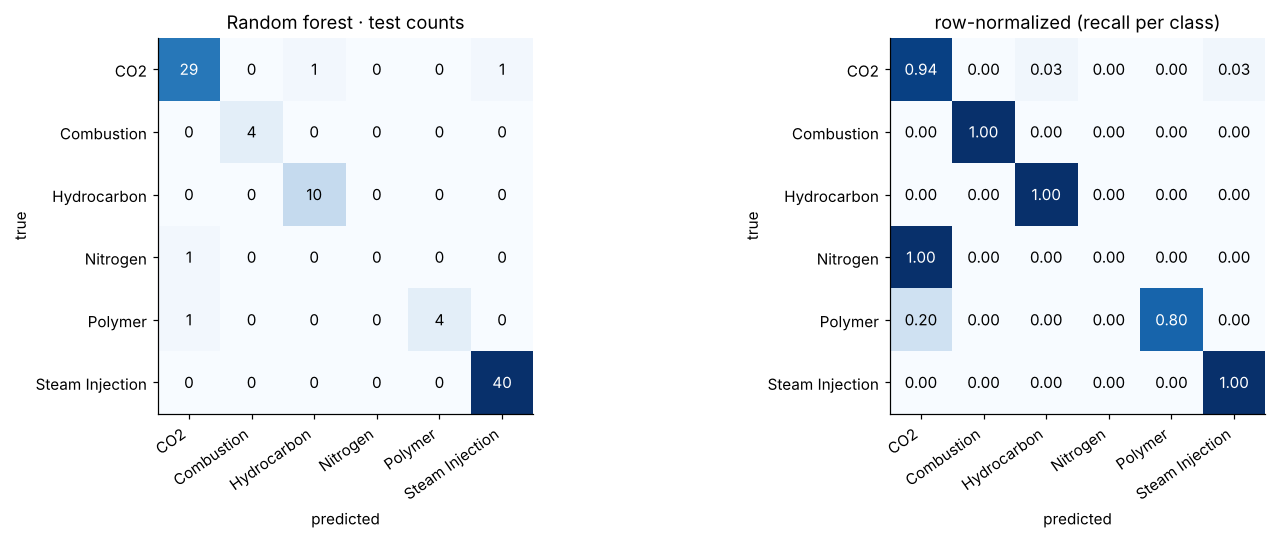

                 precision    recall  f1-score   support

            CO2       0.94      0.94      0.94        31
     Combustion       1.00      1.00      1.00         4
    Hydrocarbon       0.91      1.00      0.95        10
       Nitrogen       0.00      0.00      0.00         1
        Polymer       1.00      0.80      0.89         5
Steam Injection       0.98      1.00      0.99        40

       accuracy                           0.96        91
      macro avg       0.80      0.79      0.79        91
   weighted avg       0.95      0.96      0.95        91



In [4]:
rf = classifiers()["Random forest"].fit(X_train, y_train); p = rf.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
confusion(y_test, p, EOR_CLASSES, ax=ax[0], title="Random forest · test counts")
confusion(y_test, p, EOR_CLASSES, ax=ax[1], title="row-normalized (recall per class)", normalize=True)
plt.tight_layout(); plt.show()
from sklearn.metrics import classification_report; print(classification_report(y_test, p, zero_division=0))

### ✏️ Your turn 1 · cross-validated comparison
One 20% test set holds only ~2 Nitrogen projects, so its scores are noisy. Compare *Random forest*, *Gradient boosting*,
*SVC* and *Neural network (MLP)* with **stratified 5-fold cross-validation** (`scoring="f1_macro"`) on all data. Report mean ± std.

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
for name in ["Random forest", "Gradient boosting", "SVC", "Neural network (MLP)"]:
    s = cross_val_score(classifiers()[name], df[F_LOG], y, cv=cv, scoring="f1_macro")
    print(f"{name:<22} macro F1 {s.mean():.3f} ± {s.std():.3f}")

Random forest          macro F1 0.772 ± 0.062


Gradient boosting      macro F1 0.740 ± 0.067
SVC                    macro F1 0.735 ± 0.091


Neural network (MLP)   macro F1 0.685 ± 0.101


## 3 · Machine learning vs the expert rules
`taber_screen` applies simplified Taber, Martin & Seright (1997) criteria, the rules an engineer would use.

In [6]:
pd.DataFrame(TABER).T

,api,visc,depth,sat,perm,temp
Nitrogen,"(35, 99)","(0, 0.4)","(6000, 99999)","(40, 100)",NaN,NaN
Hydrocarbon,"(23, 99)","(0, 3)","(4000, 99999)","(30, 100)",NaN,NaN
CO2,"(22, 99)","(0, 10)","(2500, 99999)","(20, 100)",NaN,NaN
Polymer,"(15, 99)","(10, 150)","(0, 9000)","(50, 100)","(10, 1000000000.0)","(0, 200)"
Combustion,"(10, 27)","(0, 5000)","(0, 11500)","(50, 100)","(50, 1000000000.0)",NaN
Steam Injection,"(8, 25)","(20, 200000.0)","(0, 4500)","(40, 100)","(200, 1000000000.0)",NaN


Taber rules  accuracy 0.736  macro F1 0.332
Random forest accuracy 0.956  macro F1 0.794


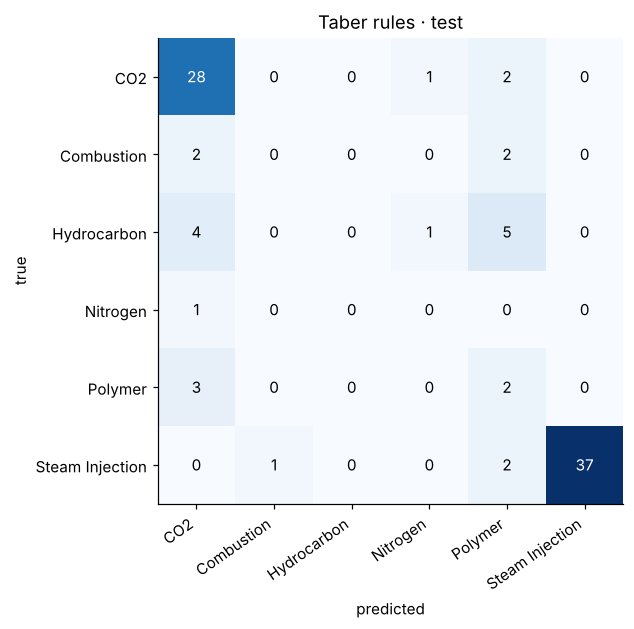

In [7]:
t = taber_screen(df.loc[te])
print("Taber rules  accuracy", round((t == y_test).mean(), 3), " macro F1", round(classification_metrics(y_test, t)["F1_macro"], 3))
print("Random forest accuracy", round((p == y_test).mean(), 3), " macro F1", round(classification_metrics(y_test, p)["F1_macro"], 3))
fig, ax = plt.subplots(figsize=(7, 5.5)); confusion(y_test, t, EOR_CLASSES, ax=ax, title="Taber rules · test"); plt.show()

The rules know nothing about this database, yet get most projects right; the model learns the operators' real
choices (for example, which light-oil reservoirs got CO₂ rather than hydrocarbon gas). Rules are transparent and work
outside the data; the model is more accurate inside it. Use both.

## 4 · Explain and screen a new field

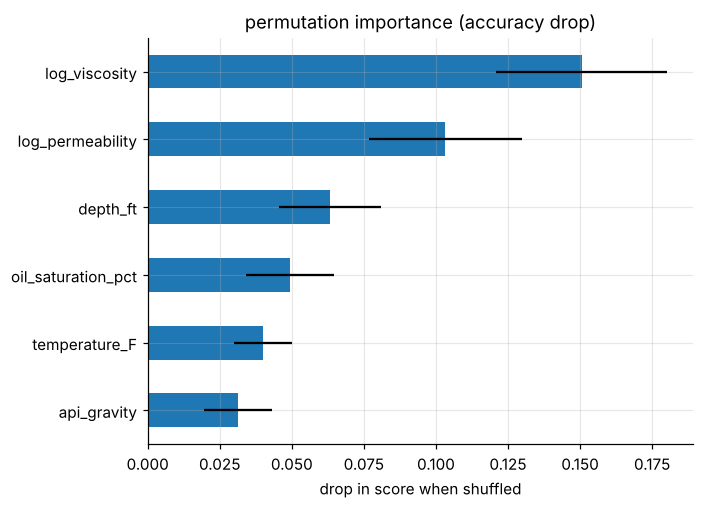

In [8]:
imp = importance(rf, X_test, y_test); plt.title("permutation importance (accuracy drop)"); plt.show()

In [9]:
new = pd.DataFrame([{"permeability_md": 100, "depth_ft": 8000, "api_gravity": 30, "viscosity_cp": 10, "temperature_F": 150, "oil_saturation_pct": 50}])
new_log = new.assign(log_permeability=np.log10(new.permeability_md), log_viscosity=np.log10(new.viscosity_cp))[F_LOG]
print("model:", rf.predict(new_log)[0], "  rules:", taber_screen(new)[0])
pd.Series(rf.predict_proba(new_log)[0], rf.classes_).sort_values(ascending=False).round(3)

model: CO2   rules: Polymer


CO2                0.490
Polymer            0.290
Hydrocarbon        0.123
Nitrogen           0.063
Steam Injection    0.027
Combustion         0.007
dtype: float64

### ✏️ Your turn 2
A heavy-oil field: permeability 1500 mD, depth 1200 ft, 12 °API, 3000 cP, 95 °F, 70 % oil saturation.
What do the model and the rules recommend, and how confident is the model? Then make the same field 6000 ft deep. What changes?

In [10]:
def screen(f):
    fl = f.assign(log_permeability=np.log10(f.permeability_md), log_viscosity=np.log10(f.viscosity_cp))[F_LOG]
    pr = pd.Series(rf.predict_proba(fl)[0], rf.classes_).sort_values(ascending=False).round(2)
    print("model:", pr.index[0], dict(pr.head(3)), "| rules:", taber_screen(f)[0])
heavy = pd.DataFrame([{"permeability_md": 1500, "depth_ft": 1200, "api_gravity": 12, "viscosity_cp": 3000, "temperature_F": 95, "oil_saturation_pct": 70}])
screen(heavy); screen(heavy.assign(depth_ft=6000))
print("At 6000 ft steam loses too much heat in the wellbore, so the rules switch to combustion.")
print("The model only follows if the database holds deep heavy-oil projects: check its probabilities.")

model: Steam Injection {'Steam Injection': np.float64(0.97), 'Combustion': np.float64(0.03), 'CO2': np.float64(0.0)} | rules: Steam Injection
model: Steam Injection {'Steam Injection': np.float64(0.73), 'Combustion': np.float64(0.1), 'CO2': np.float64(0.09)} | rules: Combustion
At 6000 ft steam loses too much heat in the wellbore, so the rules switch to combustion.
The model only follows if the database holds deep heavy-oil projects: check its probabilities.


### ✏️ Your turn 3 · class weights
Retrain the random forest with `class_weight="balanced"` and compare recall for *Nitrogen*, *Combustion* and *Polymer*.

## Key ideas
* Log-transform inputs that span decades before distance-based models.
* With imbalanced classes report macro F1 and the confusion matrix, not just accuracy.
* Cross-validate when the test set is small.
* Expert rules are a strong, explainable baseline; ML should beat them and agree with them where it matters.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score
rb = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0).fit(X_train, y_train)
for name, m in [("plain", rf), ("balanced", rb)]:
    r = recall_score(y_test, m.predict(X_test), labels=EOR_CLASSES, average=None, zero_division=0)
    print(name, dict(zip(EOR_CLASSES, r.round(2))))

plain {'CO2': np.float64(0.94), 'Combustion': np.float64(1.0), 'Hydrocarbon': np.float64(1.0), 'Nitrogen': np.float64(0.0), 'Polymer': np.float64(0.8), 'Steam Injection': np.float64(1.0)}
balanced {'CO2': np.float64(0.9), 'Combustion': np.float64(1.0), 'Hydrocarbon': np.float64(1.0), 'Nitrogen': np.float64(0.0), 'Polymer': np.float64(0.8), 'Steam Injection': np.float64(1.0)}
